# Ultrasound Vessel Scan → 3D Reconstruction — Project Report

This notebook is a **runnable report** of the ULTRASOUND project. It walks through the full pipeline on a real recorded dataset (`ultrasound_20260924_152247`, 238 B-mode frames) and shows example output images at every step: **scanning → splitting into frames → segmentation → 3D construction**.

## What this project does

The system scans a **vessel phantom** (17 cm long, ~40 mm in-plane field of view) with a SmartUS B-mode ultrasound probe and reconstructs the segmented vessels as a 3D surface:

| Step | Folder / script | What it does |
|---|---|---|
| 0 – Tracking | `0_track/track_markers.py` | Streams 3D marker / rigid-body poses of the probe from an OptiTrack Motive motion-capture system (C++ wrapper DLL via ctypes). Optional hardware step. |
| 1 – Acquisition | `1_acquire/SmartUsDisplay.py` | Live B-mode display + recorder driven by the vendor SDK (`usgfw2wrapper.dll`). All scan settings come from `1_acquire/.env`. Saves PNG snapshots and/or MP4 video into `data/`. Requires the SmartUS probe. |
| 2a – Frame extraction | `data/extract_frames.py` | Splits the recorded MP4 into one PNG per frame + a metadata JSON (`data/video2images/<stem>/`). |
| 2b – Segmentation | `2_segment/segment_vessels.py` | Pure-OpenCV segmentation of **anechoic (near-black) vessel structures**: Gaussian blur → low-intensity threshold → morphological cleanup → interior-vessel detectors (A1/A2) + a border-bulge detector for vessels cut off by the scan edge. Outputs binary masks, red overlays and per-frame component JSONs under `2_segment/output/<stem>/`. |
| 3 – 3D construction | `3_construct/construct_3d.py` | Stacks the per-frame masks into a 3D voxel volume with physical spacing (Z = scan direction, 17 cm over all frames; X/Y = in-plane, 40 mm FOV), extracts the vessel surface with marching cubes and renders it interactively in PyVista. Can export the mesh to OBJ/STL/PLY. |

**Data flow:**
`SmartUS probe → MP4 video (data/video) → per-frame PNGs (data/video2images) → masks / overlays / JSON (2_segment/output) → 3D volume + surface mesh (3_construct/output)`


## How to run

### 1. Environment
Python 3.10+ (developed on Windows 11, Python 3.14). Install the dependencies:

```bash
pip install -r requirements.txt
```

> `0_track` and `1_acquire` additionally need **hardware** (OptiTrack system / SmartUS probe) and the prebuilt vendor DLLs that ship in the repo (`0_track/bin/motive_wrapper.dll`, `1_acquire/usgfw2wrapper.dll`). Everything from frame extraction onward is pure Python.

### 2. Pipeline commands (run from the project root)

```bash
# Step 0 (optional, needs OptiTrack; close Motive.exe first):
python 0_track/track_markers.py --duration 10 --csv out/marker_log.csv

# Step 1 (needs the SmartUS probe connected):
python 1_acquire/SmartUsDisplay.py        # 'v' toggles video recording, 'q' quits

# Step 2a - split a recorded video into frames:
python data/extract_frames.py data/video/ultrasound_20260924_152247.mp4

# Step 2b - segment vessels in every frame:
python 2_segment/segment_vessels.py

# Step 3 - interactive 3D view (r = toggle spin, s = screenshot, q = quit):
python 3_construct/construct_3d.py --video-stem ultrasound_20260924_152247
```

### 3. This notebook
Run every cell top-to-bottom (VS Code: *Run All*). It only needs the **already recorded** data in `data/` and `2_segment/output/`, so no hardware is required. The segmentation and 3D steps are re-executed live on an example frame / the full mask stack, so the notebook reproduces the pipeline results itself.


In [1]:
# ----------------------------------------------------------------------
# Setup: paths + import the project modules.
# (The step folders start with a digit, so they are loaded by file path
# instead of a normal package import.)
# ----------------------------------------------------------------------
import json
from pathlib import Path

import cv2
import matplotlib
try:
    get_ipython()  # inside a notebook kernel -> render figures inline
    matplotlib.use("module://matplotlib_inline.backend_inline")
except NameError:
    matplotlib.use("Agg")     # plain script / headless fallback
import matplotlib.pyplot as plt
import numpy as np
import pyvista as pv

ROOT = Path.cwd()              # run from the project root (ULTRASOUND/)
STEM = "ultrasound_20260924_152247"

FRAMES_DIR   = ROOT / "data" / "video2images" / STEM
MASKS_DIR    = ROOT / "2_segment" / "output" / STEM / "masks"
OVERLAYS_DIR = ROOT / "2_segment" / "output" / STEM / "overlays"
JSON_DIR     = ROOT / "2_segment" / "output" / STEM / "json"
SUMMARY_JSON = ROOT / "2_segment" / "output" / "summary.json"
VIDEO        = ROOT / "data" / "video" / f"{STEM}.mp4"
VIEW3D_PNG   = ROOT / "3_construct" / "output" / "test_view.png"

def _load(name, path):
    import importlib.util
    spec = importlib.util.spec_from_file_location(name, path)
    mod = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(mod)
    return mod

seg = _load("segment_vessels", ROOT / "2_segment" / "segment_vessels.py")
con = _load("construct_3d",    ROOT / "3_construct" / "construct_3d.py")

def ensure_data():
    """Fresh-clone support: generated outputs are git-ignored, so re-create
    them from the committed video if they are missing."""
    global frame_paths
    if not list(FRAMES_DIR.glob(f"{STEM}_frame_*.png")):
        print("Frames not found - extracting from video (data/extract_frames.py logic) ...")
        import sys as _sys
        _sys.path.insert(0, str(ROOT / "data"))
        import extract_frames as ef
        ef.extract_frames(VIDEO, FRAMES_DIR)
    frame_paths = sorted(FRAMES_DIR.glob(f"{STEM}_frame_*.png"))
    if not list(MASKS_DIR.glob("*.png")):
        print("Masks not found - segmenting all frames (may take ~1 min) ...")
        MASKS_DIR.mkdir(parents=True, exist_ok=True)
        for p in frame_paths:
            gray = cv2.imread(str(p), cv2.IMREAD_GRAYSCALE)
            mask, _ = seg.segment_vessel(gray)
            cv2.imwrite(str(MASKS_DIR / p.name), mask)

ensure_data()
print(f"Project root : {ROOT}")
print(f"Frames found : {len(frame_paths)}  (data/video2images/{STEM}/)")
print(f"Masks found  : {len(list(MASKS_DIR.glob('*.png')))}  (2_segment/output/{STEM}/masks/)")

Project root : c:\Users\ardian\Documents\ULTRASOUND
Frames found : 238  (data/video2images/ultrasound_20260924_152247/)
Masks found  : 238  (2_segment/output/ultrasound_20260924_152247/masks/)


## Step 1 — Scanning (B-mode acquisition)

`1_acquire/SmartUsDisplay.py` opens the SmartUS probe through the vendor DLL, applies the scan settings from `1_acquire/.env` (512×512 B image, gain 90, depth 40 mm, high line density) and records the live B-mode feed to MP4.

The figure below shows **six frames sampled across the whole scan**. As the probe is translated along the 17 cm phantom, the dark (anechoic) vessel cross-sections move through the image. Note the bright speckle texture of the tissue and the black out-of-scan margins around the beam footprint.

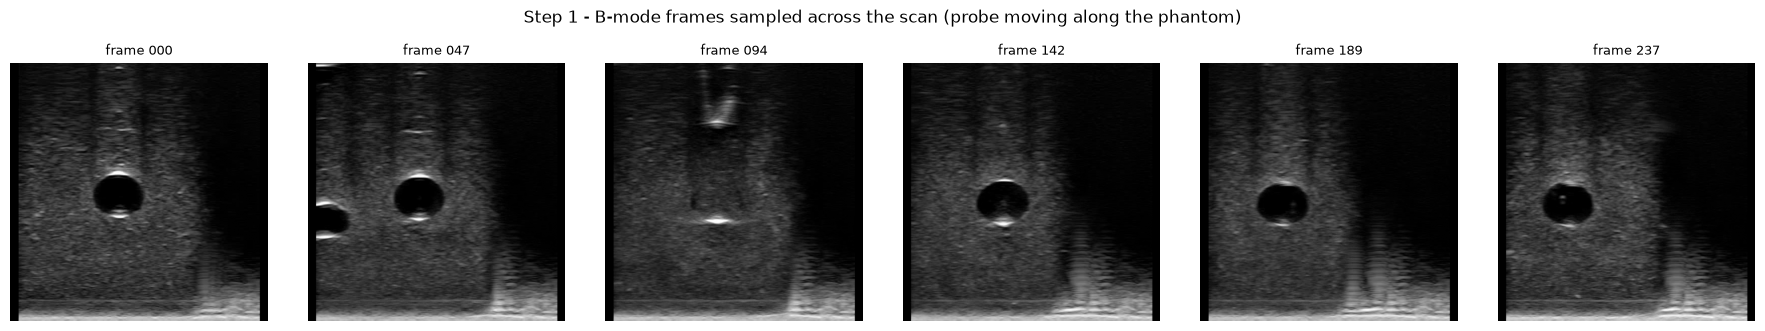

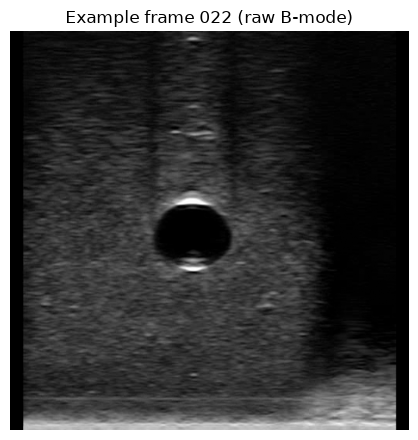

In [2]:
# Example: six frames sampled evenly across the scan sweep.
idx = np.linspace(0, len(frame_paths) - 1, 6).astype(int)
fig, axes = plt.subplots(1, 6, figsize=(18, 3.2), sharex=True, sharey=True)
for ax, i in zip(axes, idx):
    img = cv2.cvtColor(cv2.imread(str(frame_paths[i])), cv2.COLOR_BGR2GRAY)
    ax.imshow(img, cmap="gray")
    ax.set_title(f"frame {i:03d}", fontsize=9)
    ax.axis("off")
fig.suptitle("Step 1 - B-mode frames sampled across the scan (probe moving along the phantom)", y=1.02)
plt.tight_layout()
plt.show()

# The single example frame used for all later steps:
EX = 22
ex_img = cv2.cvtColor(cv2.imread(str(frame_paths[EX])), cv2.COLOR_BGR2GRAY)
plt.figure(figsize=(4.5, 4.5))
plt.imshow(ex_img, cmap="gray")
plt.title(f"Example frame {EX:03d} (raw B-mode)")
plt.axis("off")
plt.tight_layout()
plt.show()

## Step 2 — Splitting the video into frames

`data/extract_frames.py` decodes the recorded MP4 with OpenCV and writes one PNG per frame (`<stem>_frame_%06d.png`) plus a metadata JSON. This is what turns the *scan* (a video) into the *frame stack* that segmentation consumes.

{
  "source_file": "ultrasound_20260924_152247.mp4",
  "fps": 25.0,
  "frame_count": 238,
  "width_px": 512,
  "height_px": 512,
  "extracted_frames": 238
}


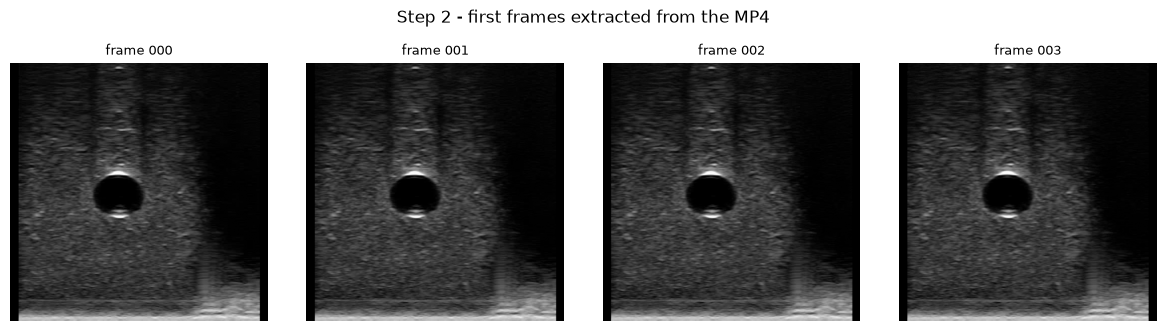

In [3]:
# Video metadata (same logic as data/extract_frames.py).
cap = cv2.VideoCapture(str(VIDEO))
meta = {
    "source_file": VIDEO.name,
    "fps": round(cap.get(cv2.CAP_PROP_FPS), 3),
    "frame_count": int(cap.get(cv2.CAP_PROP_FRAME_COUNT)),
    "width_px": int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)),
    "height_px": int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT)),
}
cap.release()
meta["extracted_frames"] = len(frame_paths)   # ground truth: files on disk
print(json.dumps(meta, indent=2))

# First four extracted frames - consecutive slices of the video:
fig, axes = plt.subplots(1, 4, figsize=(12, 3.2), sharex=True, sharey=True)
for ax, i in zip(axes, range(4)):
    img = cv2.cvtColor(cv2.imread(str(frame_paths[i])), cv2.COLOR_BGR2GRAY)
    ax.imshow(img, cmap="gray")
    ax.set_title(f"frame {i:03d}", fontsize=9)
    ax.axis("off")
fig.suptitle("Step 2 - first frames extracted from the MP4", y=1.02)
plt.tight_layout()
plt.show()

## Step 3 — Segmentation of vessel structures

`2_segment/segment_vessels.py` is pure OpenCV (no deep learning). Vessel interiors are **anechoic** — nearly black — so the detector is:

1. Gaussian blur (5×5) to suppress speckle,
2. fixed low-intensity threshold (`DARK_THRESHOLD = 15/255`) — more robust than Otsu on dark frames,
3. morphological open/close to kill isolated noise pixels,
4. **Detector A** — interior vessels: plain connected components not touching the image border (A1), plus an erode → border-filter → dilate "seed" logic that keeps thick vessel cores while dropping thin out-of-scan shadow strips (A2); candidates must pass area / median-intensity / solidity / elongation filters,
5. **Detector B** — edge-cut vessels: for each image border with a margin strip of plausible width, rows where the dark region penetrates significantly beyond the baseline strip width are kept as partial vessels.

Outputs per frame: binary `masks/`, red-highlighted `overlays/`, and component statistics in `json/`.

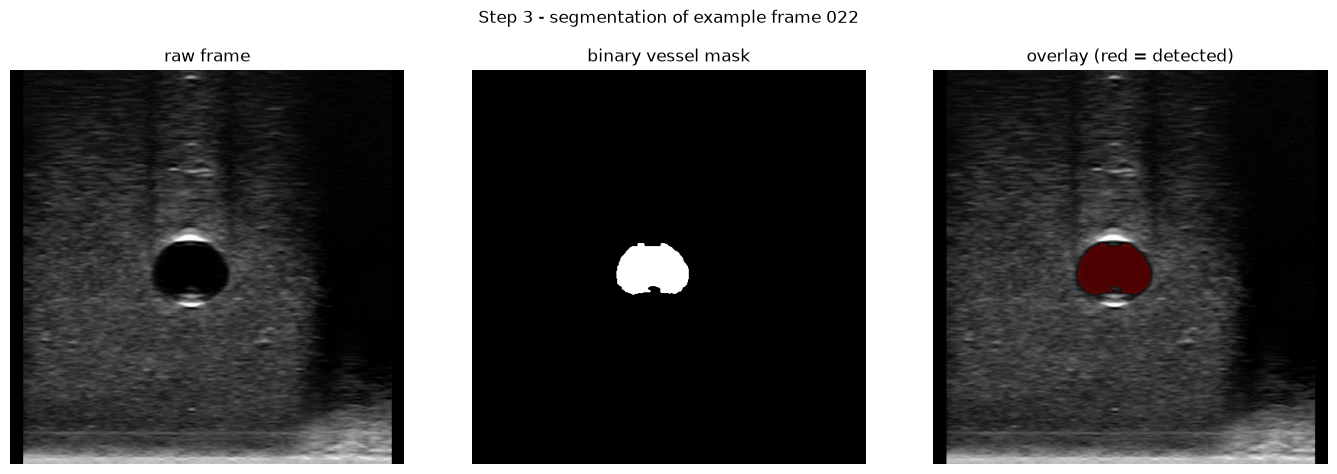

{
  "image_size": [
    512,
    512
  ],
  "num_vessels": 1,
  "total_vessel_area_px": 4972,
  "components": [
    {
      "id": 1,
      "bbox": [
        188,
        225,
        94,
        67
      ],
      "area_px": 4972,
      "area_frac": 0.019,
      "solidity": 0.957,
      "aspect_ratio_w_h": 1.4
    }
  ]
}


In [4]:
# Re-run the project's own segmentation on the example frame (live).
mask, stats = seg.segment_vessel(ex_img)
overlay = seg.make_overlay(ex_img, mask)

fig, axes = plt.subplots(1, 3, figsize=(14, 4.6))
axes[0].imshow(ex_img, cmap="gray")
axes[0].set_title("raw frame")
axes[1].imshow(mask, cmap="gray")
axes[1].set_title("binary vessel mask")
axes[2].imshow(cv2.cvtColor(overlay, cv2.COLOR_BGR2RGB))
axes[2].set_title("overlay (red = detected)")
for a in axes:
    a.axis("off")
fig.suptitle(f"Step 3 - segmentation of example frame {EX:03d}", y=1.02)
plt.tight_layout()
plt.show()

print(json.dumps(stats, indent=2))

### ⚠️ Comment on the segmentation result

The segmentation **does not come out clean** on this dataset:

- The detected region is **ragged and blob-like** rather than a smooth, well-defined lumen — the mask edges follow speckle fluctuations instead of the true vessel wall.
- The **vascular structure in the middle of the image looks like noise**: it is small, speckled and low-contrast against the tissue, so the threshold-based detector cannot separate it reliably from background speckle. As a result the central vessel **cannot be scanned / segmented properly** — it appears as an irregular blob (or disappears entirely in some frames) instead of a consistent cross-section.
- Because each frame's mask is imperfect and slightly different, stacking them produces the **fragmented, broken tube** visible in the 3D result below (gaps between ~4 cm and ~8 cm along the scan axis).

Likely causes / possible fixes: adapt `DARK_THRESHOLD` per frame, add stronger pre-smoothing tuned to the vessel diameter, use region-growing or a small CNN for the lumen, and register frames before stacking (probe motion is only approximated by equal frame spacing — see `0_track` for true pose data).

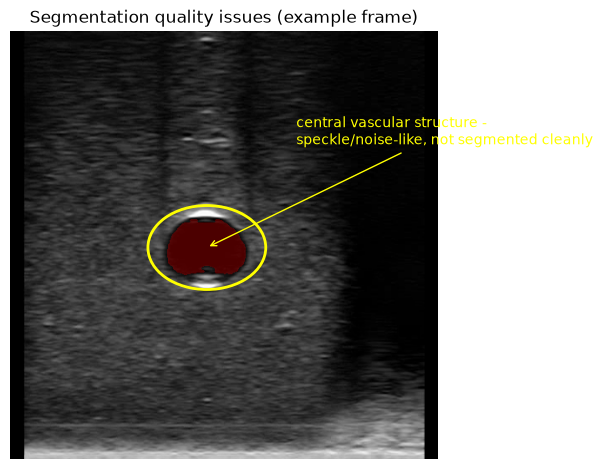

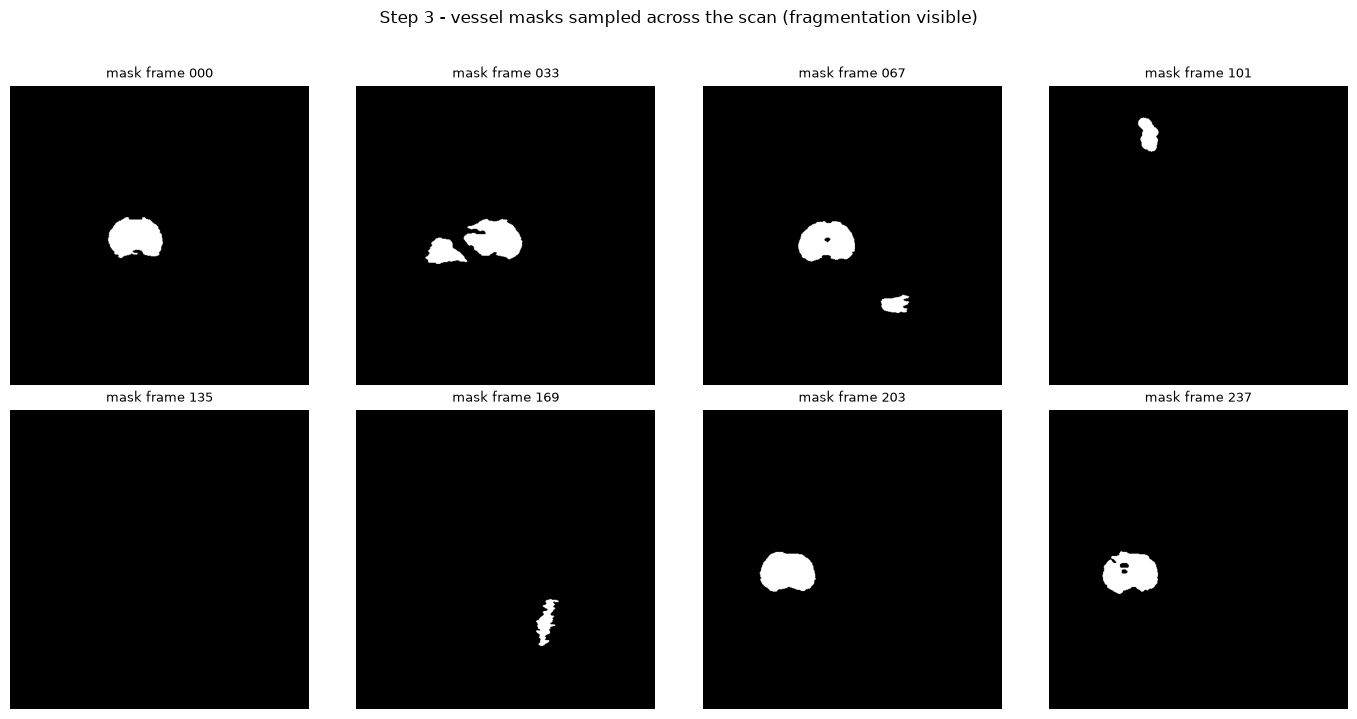

In [5]:
# Annotate the problem areas on the example overlay.
from matplotlib.patches import Ellipse

ov = cv2.cvtColor(overlay, cv2.COLOR_BGR2RGB)
fig, ax = plt.subplots(figsize=(6, 6))
ax.imshow(ov)
if stats["components"]:
    x, y, cw, ch = stats["components"][0]["bbox"]
    e = Ellipse((x + cw / 2, y + ch / 2), width=cw * 1.5, height=ch * 1.5,
                fill=False, edgecolor="yellow", linewidth=2)
    ax.add_patch(e)
    ax.annotate("central vascular structure -\nspeckle/noise-like, not segmented cleanly",
                xy=(x + cw / 2, y + ch / 2), xytext=(x + cw + 60, y - 90),
                color="yellow", fontsize=10,
                arrowprops=dict(arrowstyle="->", color="yellow"))
ax.set_title("Segmentation quality issues (example frame)")
ax.axis("off")
plt.tight_layout()
plt.show()

# Masks across the scan - note the fragmentation / missing frames:
masks = sorted(MASKS_DIR.glob(f"{STEM}_frame_*.png"))
idx = np.linspace(0, len(masks) - 1, 8).astype(int)
fig, axes = plt.subplots(2, 4, figsize=(14, 7), sharex=True, sharey=True)
for ax, i in zip(axes.ravel(), idx):
    m = cv2.imread(str(masks[i]), cv2.IMREAD_GRAYSCALE)
    ax.imshow(m, cmap="gray")
    fno = int(masks[i].stem.rsplit("_", 1)[-1])
    ax.set_title(f"mask frame {fno:03d}", fontsize=9)
    ax.axis("off")
fig.suptitle("Step 3 - vessel masks sampled across the scan (fragmentation visible)", y=1.02)
plt.tight_layout()
plt.show()

## Step 4 — Constructing the 3D representation

`3_construct/construct_3d.py` stacks the per-frame masks into a voxel volume with physical spacing:

- **Z axis** = scan direction: `dz = 17 cm / (n_frames − 1)` (phantom length),
- **X/Y axes** = in-plane image axes: `dx = dy = 40 mm FOV / (size − 1)`,

then extracts the vessel surface with **marching cubes** (iso-value 127.5, between the 0/255 voxel values) and renders it in PyVista, colored by scan position. The mesh can be exported (`--export-mesh vessels.obj`).

The figure below is re-rendered **live from the mask stack** (off-screen), followed by the saved screenshot from an interactive run for comparison.

Frames: 238 | image: 512x512 px | vessel voxels: 1029305
Spacing (cm): x=0.0078 y=0.0078 z=0.0717


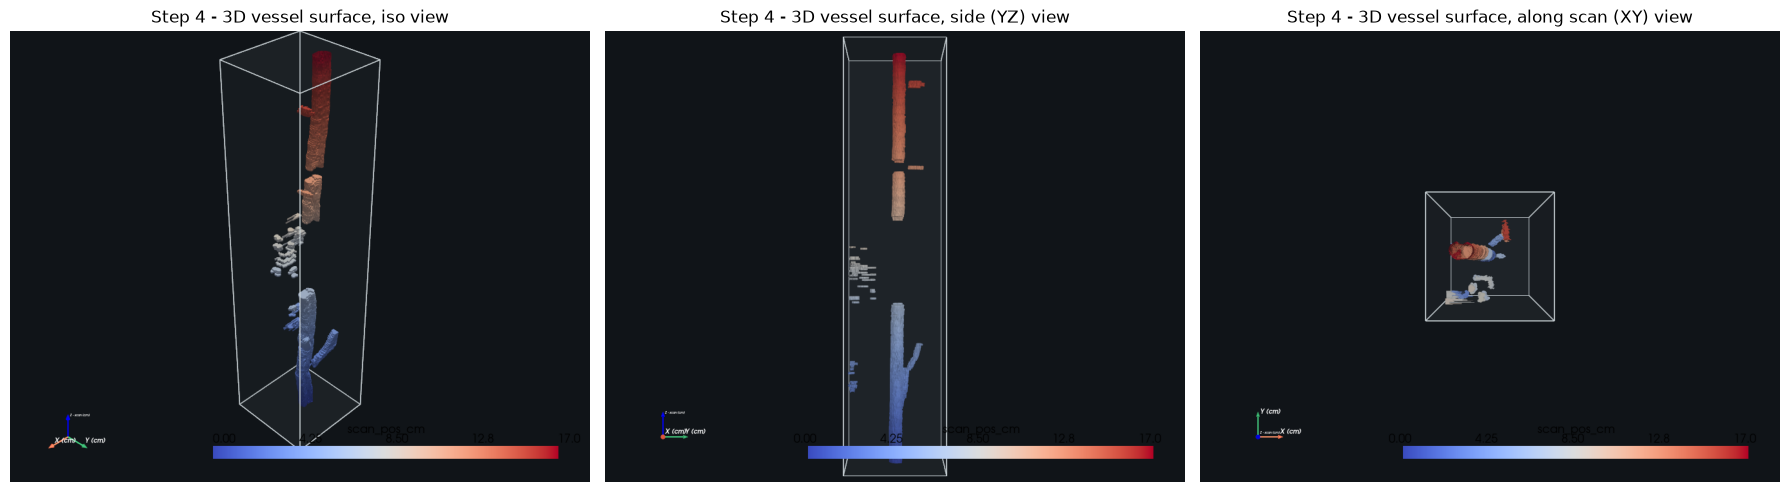

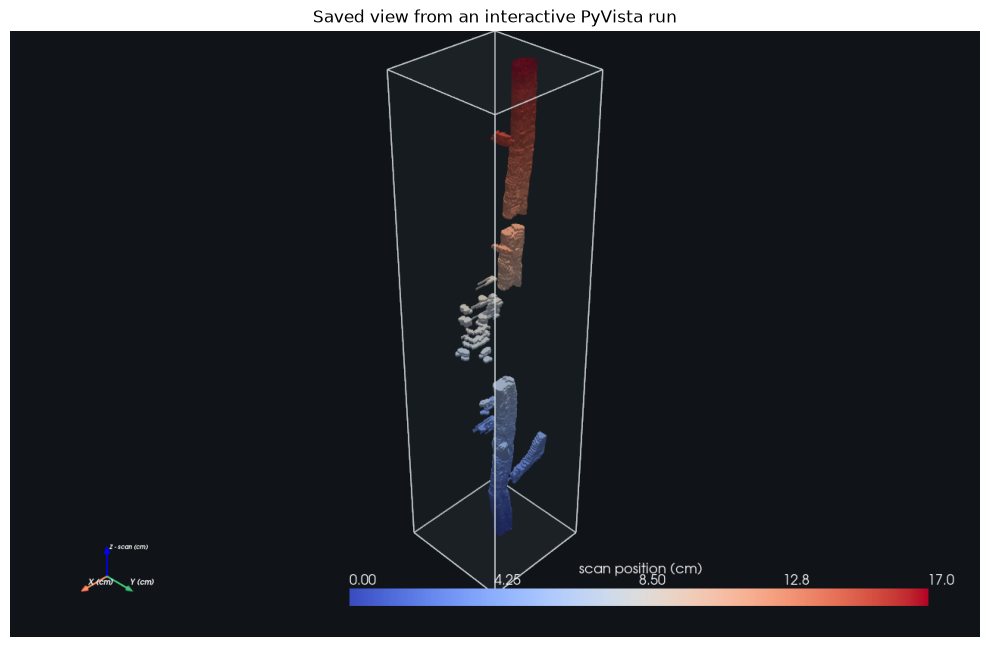

In [6]:
# Rebuild the volume from the saved masks and render it off-screen.
stack = con.load_mask_stack(MASKS_DIR)
volume, surface, (dx, dy, dz) = con.build_volume(stack, length_cm=17.0, fov_cm=4.0)
print(f"Frames: {stack.shape[0]} | image: {stack.shape[2]}x{stack.shape[1]} px | "
      f"vessel voxels: {int((stack > 0).sum())}")
print(f"Spacing (cm): x={dx:.4f} y={dy:.4f} z={dz:.4f}")

plotter = pv.Plotter(off_screen=True, window_size=(900, 700))
plotter.set_background("#101418")
plotter.add_mesh(surface, scalars="scan_pos_cm", cmap="coolwarm", show_edges=False)
box = pv.Box(bounds=volume.bounds)
plotter.add_mesh(box, color="#8899aa", opacity=0.08)
plotter.add_mesh(box.outline(), color="#cfd8dc", line_width=1.5)
plotter.add_axes(color="white", xlabel="X (cm)", ylabel="Y (cm)", zlabel="Z - scan (cm)")

view_fns = [None, plotter.view_yz, plotter.view_xy]   # iso / side (YZ) / along scan (XY)
views = ["iso", "side (YZ)", "along scan (XY)"]
shots = []
for name, fn in zip(views, view_fns):
    plotter.reset_camera()
    if fn is not None:
        fn()
    shots.append(plotter.screenshot(return_img=True))
plotter.close()

fig, axes = plt.subplots(1, 3, figsize=(18, 6.5))
for ax, title_v, s in zip(axes, views, shots):
    ax.imshow(s)
    ax.set_title(f"Step 4 - 3D vessel surface, {title_v} view")
    ax.axis("off")
plt.tight_layout()
plt.show()

# Saved screenshot from the interactive run (if available):
if VIEW3D_PNG.exists():
    plt.figure(figsize=(10, 6.5))
    plt.imshow(plt.imread(str(VIEW3D_PNG)))
    plt.title("Saved view from an interactive PyVista run")
    plt.axis("off")
    plt.tight_layout()
    plt.show()
else:
    print("(No saved screenshot found - run 3_construct/construct_3d.py interactively to create one.)")

## Summary

| Step | Example output shown | Where it lives |
|---|---|---|
| Scanning | B-mode frames across the sweep | `data/video/`, `data/images/` |
| Splitting | one PNG per frame + metadata JSON | `data/video2images/<stem>/` |
| Segmentation | binary mask, red overlay, component JSON per frame | `2_segment/output/<stem>/{masks,overlays,json}/` |
| 3D construction | marching-cubes surface mesh (OBJ/STL exportable) + PyVista screenshots | `3_construct/output/` |

**Result quality:** the pipeline runs end-to-end, but segmentation of this phantom is **not clean** — the central vascular structure is speckle/noise-like and cannot be segmented consistently frame-to-frame, which shows up as a fragmented, broken tube in the 3D reconstruction (see the comment after Step 3).